In [2]:
# Author: Till Zemann
# License: MIT License
from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C
from net.dale_util import RL_Hidden_Buffer
from rl.phase_detect import tag_lunar_lander_phases_batch, tag_lunar_lander_phases_batch_2
import cv2

1.12.0


In [3]:
import gymnasium as gym
import numpy as np

def main():
    env = gym.make("LunarLander-v3", max_episode_steps=500, render_mode="rgb_array")
    print("gym version:", gym.__version__)
    obs, info = env.reset()
    print("obs shape:", obs.shape)

    for t in range(100):
        frame = env.render()
        if t == 0:
            print("frame shape:", frame.shape)
        obs, r, terminated, truncated, info = env.step(env.action_space.sample())
        if terminated or truncated:
            obs, info = env.reset()

    env.close()
    print("done")

if __name__ == "__main__":
    main()


/cephfs/wangjiyi/miniconda3/envs/mixer/lib/python3.9/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


gym version: 1.1.1
obs shape: (8,)
frame shape: (400, 600, 3)
done


In [4]:

def test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type, n_seed):
    env_name = "LunarLander-v3"

    # env_name = "MountainCar-v0"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    hidden_size = 64
    # environment setup
    n_envs = 1
    env = gym.make(env_name, max_episode_steps=500, render_mode='rgb_array')

    obs_shape = env.observation_space.shape[0]
    print('obs_shape', obs_shape)
    action_shape = env.action_space.n
    action_dim = 1
    state, info = env.reset()
    frame = env.render()
    print('frame shape:', frame.shape)
    scale = 4
    H_new = frame.shape[0]//scale
    W_new = frame.shape[1]//scale
    new_frame_shape = (H_new, W_new, frame.shape[2])

    # actor_weights_path = f"weights/{configuration}/actor_weights.h5"
    # critic_weights_path = f"weights/{configuration}/critic_weights.h5"
    # if configuration == 'simple':
    #     info_path = f'./result/lunarlander/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    # else:
    #     info_path = f'./result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'

    with open(info_path, 'rb') as f:
        info = pkl.load(f)
    net_state_dicts = info['net_state_dict']
    reward_ar = np.zeros((n_seed, n_showcase_episodes))
    for seed in range(n_seed):
        buffer = RL_Hidden_Buffer(12000, obs_shape, action_dim, hidden_size, 2, new_frame_shape)
        buffer_path = info_path.replace('.pkl', f'_buffer{seed}.pkl')
        device = 'cpu'
        torch.manual_seed(seed)
        np.random.seed(seed)
        agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size,
                    configuration, simple_type=simple_type, ei_type=ei_type)
        agent.load_state_dict(net_state_dicts[seed])
        agent.eval()
        agent.to(device)

        for episode in range(n_showcase_episodes):
            # print(f"starting episode {episode}...")
            # get an initial state
            state, info = env.reset()
            # play one episode
            done = False
            hidden = agent.reset_hidden(batch_size=1)
            # hidden = (torch.zeros((1, hidden_size), device=device), torch.zeros((1, hidden_size), device=device))
            rewards = 0.
            while not done:
                # select an action A_{t} using S_{t} as input for the agent
                tp = [None] * 6
                tp[0] = state
                frame_single = env.render()
                tp[5] = cv2.resize(frame_single, (W_new, H_new), interpolation=cv2.INTER_AREA)
                tp[2] = hidden
                with torch.no_grad():
                    action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)
                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                # print('action:', action)
                state, reward, terminated, truncated, info = env.step(action.item())
                tp[1] = action
                tp[3] = reward
                rewards += reward

                # update if the environment is done
                done = terminated or truncated

                tp[4] = done
                buffer.add(*tp)
                # h_critic, h_actor = new_hidden
                # h_critic = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_critic).to(device), h_critic)
                # h_actor = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_actor).to(device), h_actor)
                # hidden = (h_critic, h_actor)
                hidden = agent.reset_hidden_on_done(new_hidden, [terminated])
            reward_ar[seed, episode] = rewards
            print(f"Seed {seed}, episode {episode}, reward: {rewards}")
        buffer.save(buffer_path)
    env.close()
    return reward_ar

In [5]:
# from importlib import simple


# actor_lrs = [0.0003, 0.001, 0.003]
# critic_lrs = [0.0015, 0.005, 0.015]
actor_lrs = [0.001]
critic_lrs = [0.005]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 1
reward_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes))
simple_type = 'rnn'
ei_type = 'eisep'
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        for i, configuration in enumerate(configurations):
            print(f"Testing configuration: {configuration}, actor_lr: {actor_lr}, critic_lr: {critic_lr}")
            reward_ars[a,c,i] = test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type, n_seed)
            print(reward_ars[a,c,i])
# path = './result/lunarlander/dbpn/reward_ars.npy'
# os.makedirs(os.path.dirname(path), exist_ok=True)


Testing configuration: simple, actor_lr: 0.001, critic_lr: 0.005
obs_shape 8
frame shape: (400, 600, 3)
Using <class 'net.rnncell_variant.SimpleRNNCell'> RNN for actor and critic
Seed 0, episode 0, reward: 9.122053029866496
Seed 0, episode 1, reward: -1.8733565110322579
Seed 0, episode 2, reward: 17.16791879199818
Seed 0, episode 3, reward: 38.75670434374641
Seed 0, episode 4, reward: 38.61108197650819
Seed 0, episode 5, reward: 26.72192371399459
Seed 0, episode 6, reward: 23.21914933987059
Seed 0, episode 7, reward: -5.28110338519559
Seed 0, episode 8, reward: 32.21852436130659
Seed 0, episode 9, reward: 25.90891648301957
Seed 0, episode 10, reward: 16.198227210523783
Seed 0, episode 11, reward: 41.15960567009574
Seed 0, episode 12, reward: -6.8575306202145585
Seed 0, episode 13, reward: 31.226701565884877
Seed 0, episode 14, reward: -21.61959517972318
Seed 0, episode 15, reward: 36.60496679752804
Seed 0, episode 16, reward: 19.192293903998443
Seed 0, episode 17, reward: 34.6986822485

In [6]:
buffer = RL_Hidden_Buffer(10000)
simple_type = 'rnn'
ei_type = 'eisep'
configuration = 'simple'
actor_lr = 0.001
critic_lr = 0.005

info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'

buffer_path = info_path.replace('.pkl', '_buffer0.pkl')
buffer.load(buffer_path)
# buffer_phase = np.load('buffer_phase.npy')
# print(buffer_phase.shape)
print(buffer.state.shape)
print(buffer.ptr, buffer.n_h)
print(buffer.frame.shape)

./rl/result/lunarlander/simple_rnn_ei_eisep/critic_0.005_actor_0.001/simple_buffer0.pkl size: 10000
(12000, 8)
10000 2
(12000, 100, 150, 3)


In [7]:
buffer_frame = buffer.frame[:buffer.ptr]/255  # [L, 40, 60, 3]
buffer_state = buffer.state[:buffer.ptr]
buffer_action = buffer.action[:buffer.ptr]
buffer_done = buffer.done[:buffer.ptr]
buffer_reward = buffer.reward[:buffer.ptr]
buffer_phase = tag_lunar_lander_phases_batch_2(buffer_state, buffer_action, buffer_done)  # [L,]
print(buffer_phase.shape)
print(np.bincount(buffer_phase))
print(buffer_frame[0,...,0])
print(buffer_action.shape)

(10000,)
[4081 5475  444]
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]]
(10000, 1)


In [8]:

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

si = 0
ei = 1500
frames = buffer_frame[si:ei]
phases = buffer_phase[si:ei]
rewards = np.cumsum(buffer_reward[si:ei])
states = buffer_state[si:ei]
dones = buffer_done[si:ei]
actions = buffer_action[si:ei]
print(phases)
phase_names = ['Free fall', 'Braking', 'Horizontal align', 'Touchdown prep', 'Landed', 'Crash']
action_names = ['Nothing', 'Left Engine', 'Main Engine', 'Right Engine']
L = len(frames)

fig, ax = plt.subplots(figsize=(8,8))
im = ax.imshow(frames[0])
ax.axis("off")

def update(i):
    im.set_array(frames[i])
    ax.set_title(f"Frame {i}, Phase:{phase_names[phases[i]]}, Action:{action_names[int(actions[i].item())]}\n"\
                 f"x:{states[i,0]:.2f}, y:{states[i,1]:.2f}, vx:{states[i,2]:.2f}, vy:{states[i,3]:.2f}\n"\
                 f"a:{states[i,4]:.2f}, va:{states[i,5]:.2f}, LC:{states[i,6]:.0f}, RC:{states[i,7]:.0f}\n"\
                f"reward:{float(rewards[i]):.2f}, done:{int(dones[i])}", fontsize=16)
    return [im]

ani = FuncAnimation(fig, update, frames=L, interval=33)

writer = FFMpegWriter(fps=10)
ani.save("./rl/video_from_buffer.mp4", writer=writer)

plt.close(fig)
print("Saved ./rl/video_from_buffer.mp4")


[0 0 0 ... 0 0 0]
Saved ./rl/video_from_buffer.mp4


In [25]:
states = buffer_state[si:ei]
print(states[-3])

[-0.10204773  0.00140331 -0.04073658 -0.0026654   0.00025785  0.04016757
  0.          0.        ]


(10000, 4)
(10000, 12)
(10000, 64)
x: min -0.63, max 0.82,           mean -0.07, std 0.35
y: min 0.38, max 1.52,           mean 0.95, std 0.23
vx: min -0.80, max 0.77,           mean -0.02, std 0.16
vy: min -0.56, max 0.50,           mean -0.07, std 0.08
a: min -0.29, max 0.24,           mean -0.00, std 0.05
va: min -0.37, max 0.42,           mean -0.00, std 0.07


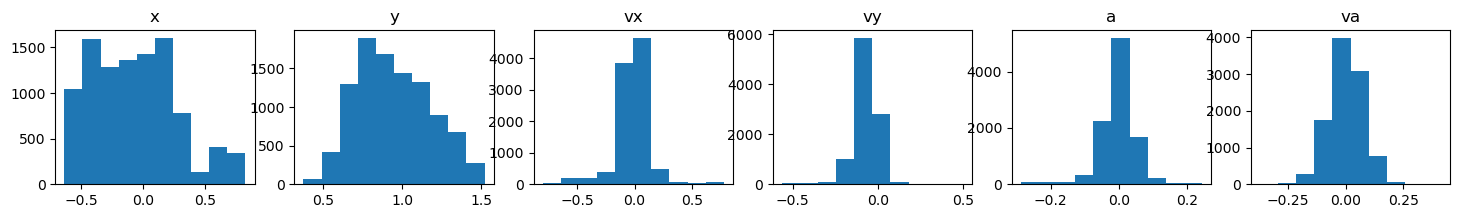

In [ ]:
n_action = int(buffer.action.max()+1)
feature_dim = buffer.state.shape[-1] + n_action
buffer_state = buffer.state[:buffer.ptr]
buffer_action = buffer.action[:buffer.ptr]
buffer_done = buffer.done[:buffer.ptr]
buffer_action_onehot = np.eye(n_action)[buffer_action.astype(np.int64).squeeze(-1)]
print(buffer_action_onehot.shape)
features = np.concatenate([buffer_state, buffer_action_onehot], axis=-1)
print(features.shape)
buffer_hidden = buffer.hidden_state[:buffer.ptr,0]
print(buffer_hidden.shape)
### up is positive y velocity
fig, ax = plt.subplots(1,6, figsize=(18,2))
tick_names = ['x', 'y', 'vx', 'vy', 'a', 'va', 'lc', 'rc']
for i in range(6):
    ax[i].hist(buffer_state[:,i])
    print(f'{tick_names[i]}: min {buffer_state[:,i].min():.2f}, max {buffer_state[:,i].max():.2f}, \
          mean {buffer_state[:,i].mean():.2f}, std {buffer_state[:,i].std():.2f}')
    ax[i].set_title(tick_names[i])
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from responses import start

# ---------------------------------------------------------
# 1. Load trajectory components
# ---------------------------------------------------------
start_idx = 500
end_idx = 1000
states = buffer_state[start_idx:end_idx]
phases = buffer_phase[start_idx:end_idx]
actions = buffer_action[start_idx:end_idx]
rewards = buffer.reward[start_idx:end_idx]
print(states.shape, actions.shape, phases.shape, rewards.shape)
L = states.shape[0]

# ---------------------------------------------------------
# 2. Set up the figure
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.set_xlabel("x")
ax.set_ylabel("y")

# ground line
ax.axhline(0.0, linestyle="--")

# body and legs
lander_body, = ax.plot([], [], linewidth=2)
left_leg,    = ax.plot([], [], linewidth=2)
right_leg,   = ax.plot([], [], linewidth=2)
flame_main, = ax.plot([], [], color="orange", linewidth=3)
flame_left, = ax.plot([], [], color="orange", linewidth=3)
flame_right, = ax.plot([], [], color="orange", linewidth=3)

phase_names = ['Free', 'Brake', 'Horiz', 'Prep', 'Land', 'Crash']
# ---------------------------------------------------------
# 3. Geometry helper
# ---------------------------------------------------------
def lander_geometry_from_state(s):
    x, y, vx, vy, theta, vtheta, leg1, leg2 = s
    w = 0.4
    h = 0.6

    corners = np.array([
        [-w/2, -h/2],
        [ w/2, -h/2],
        [ w/2,  h/2],
        [-w/2,  h/2],
        [-w/2, -h/2],
    ])

    c, s_ = np.cos(theta), np.sin(theta)
    R = np.array([[c, -s_],
                  [s_,  c]])
    body = corners @ R.T + np.array([x, y])

    leg_len = 0.35
    left_anchor_body  = np.array([-w/4, -h/2])
    right_anchor_body = np.array([ w/4, -h/2])
    left_tip_body  = left_anchor_body  + np.array([-leg_len * 0.3, -leg_len])
    right_tip_body = right_anchor_body + np.array([ leg_len * 0.3, -leg_len])

    left_leg_body  = np.vstack([left_anchor_body,  left_tip_body ]) @ R.T + np.array([x, y])
    right_leg_body = np.vstack([right_anchor_body, right_tip_body]) @ R.T + np.array([x, y])

    return (
        body[:, 0], body[:, 1],
        left_leg_body[:, 0], left_leg_body[:, 1],
        right_leg_body[:, 0], right_leg_body[:, 1],
        leg1, leg2
    )

# ---------------------------------------------------------
# 4. Animation functions
# ---------------------------------------------------------
def init():
    lander_body.set_data([], [])
    left_leg.set_data([], [])
    right_leg.set_data([], [])
    flame_main.set_data([], [])
    flame_left.set_data([], [])
    flame_right.set_data([], [])

    ax.set_title("")  # empty title initially
    return lander_body, left_leg, right_leg, flame_main, flame_left, flame_right

def update(frame_idx):
    s = states[frame_idx]
    action = actions[frame_idx]
    (bx, by, llx, lly, rlx, rly, leg1, leg2) = lander_geometry_from_state(s)

    lander_body.set_data(bx, by)
    left_leg.set_data(llx, lly)
    right_leg.set_data(rlx, rly)

    left_leg.set_color("green" if leg1 > 0.5 else "black")
    right_leg.set_color("green" if leg2 > 0.5 else "black")
    flame_main.set_data([], [])
    flame_left.set_data([], [])
    flame_right.set_data([], [])


    # Flame length (scaled visually)
    FL = 0.35

    # Body rotation matrix
    c, s_ = np.cos(s[4]), np.sin(s[4])
    R = np.array([[c, -s_], [s_, c]])

    # Attachment points on the lander body (in body coordinates)
    # These are approximate offsets based on Gym’s model
    main_attach  = np.array([0.0, -0.35])   # bottom center
    left_attach  = np.array([0.20, -0.20])  # right-bottom
    right_attach = np.array([-0.20, -0.20]) # left-bottom

    # Flame directions (in body coordinates)
    dir_main  = np.array([0.0, -1.0])
    dir_left  = np.array([1.0, -0.2])
    dir_right = np.array([-1.0, -0.2])

    # Convert attach points to world coords
    world_main  = R @ main_attach  + np.array([s[0], s[1]])
    world_left  = R @ left_attach  + np.array([s[0], s[1]])
    world_right = R @ right_attach + np.array([s[0], s[1]])

    # Convert tips (attach + flame)
    world_main_tip  = R @ (main_attach  + FL * dir_main )  + np.array([s[0], s[1]])
    world_left_tip  = R @ (left_attach  + FL * dir_left )  + np.array([s[0], s[1]])
    world_right_tip = R @ (right_attach + FL * dir_right) + np.array([s[0], s[1]])

    # Draw based on action
    if action == 2:      # main engine
        flame_main.set_data([world_main[0], world_main_tip[0]],
                            [world_main[1], world_main_tip[1]])

    elif action == 1:    # left engine (fires rightwards)
        flame_left.set_data([world_left[0], world_left_tip[0]],
                            [world_left[1], world_left_tip[1]])

    elif action == 3:    # right engine (fires leftwards)
        flame_right.set_data([world_right[0], world_right_tip[0]],
                            [world_right[1], world_right_tip[1]])

    # 🔵 Add the phase label
    ax.set_title(f"Phase: {phase_names[phases[frame_idx]]}, Reward: {float(rewards[frame_idx]):.2f}", fontsize=14)

    return lander_body, left_leg, right_leg, flame_main, flame_left, flame_right

# ---------------------------------------------------------
# 5. Create animation and save as mp4
# ---------------------------------------------------------
fps = 10
interval_ms = 1000 / fps

# ⚠️ Turn OFF blit so titles update correctly
anim = FuncAnimation(
    fig,
    update,
    frames=L,
    init_func=init,
    blit=False,
    interval=interval_ms,
)

writer = FFMpegWriter(fps=fps)
anim.save("lander_from_states.mp4", writer=writer)

plt.close(fig)
print("Saved video to lander_from_states.mp4")


(500, 8) (500, 1) (500,) (500, 1)
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268


In [ ]:
rewards = buffer.reward[start_idx:end_idx]
print(rewards[499])

[0.09825748]
